# Phase 1 – Baseline: Data Quality & Normal-Only Sensor Statistics
 

This single, self-contained notebook:
1. **Validates** the dataset (schema, dtypes, missing / infinite values, timestamp order & duplicates).
2. **Profiles** every sensor.
3. **Computes the reference baseline** from normal readings only (`ground_truth == 0`).
4. Splits the data into **operating states**, derives **outlier thresholds per state** and evaluates them.
5. **Checks the labels** against the official failure windows.

Every result is **displayed** in the notebook and **saved** to `outputs/metrics/`.

| Output file | Content |
|---|---|
| `baseline_integrity_summary.json` | integrity checks |
| `baseline_quality_report.csv` | per-sensor data quality |
| `sensor_baseline.csv` | normal-only statistics |
| `sensor_baseline_by_state.csv` | normal-only statistics per operating state |
| `sensor_thresholds_by_state.csv` | IQR / MAD limits per state and sensor |
| `outlier_summary_by_state.csv` | outlier rates per state |
| `official_failure_check.csv` | labels versus official failure windows |

 

## 1. Imports

In [33]:
import json
import logging
import os
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

## 2. Logging and constants

In [34]:
log = logging.getLogger("baseline")

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-8s | %(message)s",
    datefmt="%H:%M:%S",
    force=True,
)

MAD_SCALE = 1.4826


IQR_TO_STD = 1.349


LEVELS = ("warning", "critical")


METHODS = ("iqr", "mad")


DEFAULT_OFFICIAL_FAILURES = (
    ("2020-04-18 00:00", "2020-04-18 23:59"),
    ("2020-05-29 23:30", "2020-05-30 06:00"),
    ("2020-06-05 10:00", "2020-06-07 14:30"),
    ("2020-07-15 14:30", "2020-07-15 19:00"),
)

## 3. Configuration class
`BaselineConfig` documents every option. Nothing to edit here.

In [35]:
@dataclass(frozen=True)
class BaselineConfig:
     
    

    data_path: Path = field(
        default_factory=lambda: Path(os.environ.get("BASELINE_DATA_PATH", "data_labeled.csv"))
    )
    output_dir: Path = Path("outputs/metrics")
    timestamp_col: str | None = "timestamp"
    label_col: str = "ground_truth"
    id_col: str | None = None
    sensors: tuple[str, ...] | None = None
    exclude_cols: tuple[str, ...] = ("segment",)
    state_col: str = "state"
    state_source_col: str = "Motor_current"
    state_labels: tuple[str, ...] = ("off", "unloaded", "loaded")
    state_edges: tuple[float, ...] = (1.0, 4.5)
    digital_max_unique: int = 2
    min_normal_rows: int = 30
    train_fraction: float = 1.0
    iqr_multipliers: tuple[float, float] = (1.5, 3.0)
    mad_multipliers: tuple[float, float] = (3.5, 6.0)
    official_failures: tuple[tuple[str, str], ...] = DEFAULT_OFFICIAL_FAILURES
    strict: bool = False

    def __post_init__(self) -> None:
        if len(self.state_labels) != len(self.state_edges) + 1:
            raise ValueError("state_labels must have exactly one more item than state_edges.")
        if list(self.state_edges) != sorted(self.state_edges):
            raise ValueError("state_edges must be in ascending order.")
        if not 0 < self.train_fraction <= 1:
            raise ValueError("train_fraction must be in (0, 1].")

    @property
    def quality_path(self) -> Path:
        return self.output_dir / "baseline_quality_report.csv"

    @property
    def baseline_path(self) -> Path:
        return self.output_dir / "sensor_baseline.csv"

    @property
    def summary_path(self) -> Path:
        return self.output_dir / "baseline_integrity_summary.json"

    @property
    def state_baseline_path(self) -> Path:
        return self.output_dir / "sensor_baseline_by_state.csv"

    @property
    def thresholds_path(self) -> Path:
        return self.output_dir / "sensor_thresholds_by_state.csv"

    @property
    def outliers_path(self) -> Path:
        return self.output_dir / "outlier_summary_by_state.csv"

    @property
    def failure_check_path(self) -> Path:
        return self.output_dir / "official_failure_check.csv"

## 4. settings
- `data_path`:  labelled CSV (or define the `BASELINE_DATA_PATH` environment variable).
- `state_edges`: cut points of `Motor_current` separating **off / unloaded / loaded**. Confirm them on the histogram in section 11.
- `train_fraction < 1.0`: learn baselines on the oldest rows and evaluate outliers on the newest rows.
- `strict = True`: raise on integrity problems instead of warning.

In [36]:
config=BaselineConfig(
    data_path=Path("data_modwindowed.csv"),
    output_dir=Path("outputs/metrics"),
)

## 5. Loading and validation

In [ ]:
class DataValidationError(Exception):
     

def load_data(cfg: BaselineConfig) -> pd.DataFrame:
     
    path = Path(cfg.data_path)
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found: {path.resolve()}")
    try:
        df = pd.read_csv(path)
    except pd.errors.EmptyDataError as exc:
        raise DataValidationError(f"File is empty: {path}") from exc
    if df.empty:
        raise DataValidationError(f"File has no rows: {path}")
    if cfg.timestamp_col and cfg.timestamp_col in df.columns:
        df[cfg.timestamp_col] = pd.to_datetime(df[cfg.timestamp_col], errors="coerce")
    log.info("Loaded %s -> %d rows x %d columns", path.name, *df.shape)
    return df


def validate_schema(df: pd.DataFrame, cfg: BaselineConfig) -> None:
    
    required = [cfg.label_col, cfg.state_source_col]
    required += [c for c in (cfg.timestamp_col, cfg.id_col) if c]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise DataValidationError(f"Required columns missing: {missing}. Available: {list(df.columns)}")

    label = df[cfg.label_col]
    if label.isna().any():
        raise DataValidationError(f"'{cfg.label_col}' contains {int(label.isna().sum())} missing values.")
    invalid = set(pd.unique(label)) - {0, 1}
    if invalid:
        raise DataValidationError(f"'{cfg.label_col}' must be 0/1, found other values: {sorted(invalid)}")
    log.info("Schema OK. Label distribution: %s", label.value_counts().sort_index().to_dict())


def infer_sensors(df: pd.DataFrame, cfg: BaselineConfig) -> list[str]:
    """Return the sensor columns: explicit from config, otherwise auto-detected."""
    non_sensor = {cfg.timestamp_col, cfg.label_col, cfg.id_col, cfg.state_col, *cfg.exclude_cols}
    non_sensor.discard(None)

    if cfg.sensors:
        absent = [c for c in cfg.sensors if c not in df.columns]
        if absent:
            raise DataValidationError(f"Configured sensors missing from data: {absent}")
        sensors = list(cfg.sensors)
    else:
        sensors = [
            c for c in df.columns
            if c not in non_sensor and pd.api.types.is_numeric_dtype(df[c])
        ]
        if not sensors:
            raise DataValidationError("No numeric sensor columns found. Set BaselineConfig.sensors.")
        log.info("Auto-detected %d sensors: %s", len(sensors), sensors)

    non_numeric = [c for c in sensors if not pd.api.types.is_numeric_dtype(df[c])]
    if non_numeric:
        raise DataValidationError(f"Sensor columns must be numeric, got non-numeric: {non_numeric}")
    return sensors


def _report(message: str, strict: bool) -> None:
 
    if strict:
        raise DataValidationError(message)
    log.warning(message)


def _check_timestamps(df: pd.DataFrame, cfg: BaselineConfig) -> dict:
    
    ts_col = cfg.timestamp_col
    timestamps = df[ts_col]
    keys = [c for c in (cfg.id_col, ts_col) if c]

    info = {
        "unparseable": int(timestamps.isna().sum()),
        "duplicate_timestamps": int(df.duplicated(subset=keys).sum()),
    }
    groups = [g for _, g in df.groupby(cfg.id_col)[ts_col]] if cfg.id_col else [timestamps]
    info["unordered_groups"] = int(sum(not g.dropna().is_monotonic_increasing for g in groups))

    if info["unparseable"]:
        _report(f"{info['unparseable']} timestamps could not be parsed.", cfg.strict)
    if info["duplicate_timestamps"]:
        _report(f"{info['duplicate_timestamps']} duplicate timestamps.", cfg.strict)
    if info["unordered_groups"]:
        _report("Timestamps are not sorted ascending.", cfg.strict)
    if timestamps.notna().any():
        info["start"], info["end"] = str(timestamps.min()), str(timestamps.max())
    return info


def check_integrity(df: pd.DataFrame, sensors: list[str], cfg: BaselineConfig) -> dict:
    """Run integrity checks and return a JSON-serialisable summary."""
    summary = {
        "rows": int(len(df)),
        "columns": int(df.shape[1]),
        "sensors": sensors,
        "dtypes": {c: str(df[c].dtype) for c in sensors},
    }

    missing = df[sensors].isna().sum()
    infinite = np.isinf(df[sensors]).sum()
    summary["missing_total"] = int(missing.sum())
    summary["inf_total"] = int(infinite.sum())
    if missing.sum():
        _report(f"Missing values in sensors: {missing[missing > 0].to_dict()}", cfg.strict)
    if infinite.sum():
        _report(f"Infinite values in sensors: {infinite[infinite > 0].to_dict()}", cfg.strict)

    summary["duplicate_rows"] = int(df.duplicated().sum())
    if summary["duplicate_rows"]:
        _report(f"{summary['duplicate_rows']} fully duplicated rows.", cfg.strict)

    if cfg.timestamp_col is None:
        log.warning("No timestamp column configured - skipping timestamp checks.")
        summary["timestamp"] = "skipped"
    else:
        summary["timestamp"] = _check_timestamps(df, cfg)

    summary["normal_rows"] = int((df[cfg.label_col] == 0).sum())
    summary["anomaly_rows"] = int((df[cfg.label_col] == 1).sum())
    log.info("Integrity checks finished.")
    return summary


def integrity_overview(summary: dict) -> pd.DataFrame:
    flat = {k: v for k, v in summary.items() if k not in ("dtypes", "sensors")}
    return pd.json_normalize(flat, sep="_").T.rename(columns={0: "value"})

## 6. Data quality report
One row per sensor over the **full** dataset (normal + anomalous).

In [ ]:
def _sensor_kind(n_unique: int, digital_max_unique: int) -> str:
    return "digital" if n_unique <= digital_max_unique else "analogue"


def build_quality_report(df: pd.DataFrame, sensors: list[str], digital_max_unique: int = 2) -> pd.DataFrame:
    rows = []
    for sensor in sensors:
        column = df[sensor]
        finite = column.replace([np.inf, -np.inf], np.nan).dropna()
        n_unique = int(finite.nunique())
        rows.append({
            "sensor": sensor,
            "dtype": str(column.dtype),
            "n_rows": len(df),
            "n_missing": int(column.isna().sum()),
            "missing_pct": round(100 * column.isna().mean(), 4),
            "n_inf": int(np.isinf(column).sum()),
            "n_unique": n_unique,
            "zero_fraction": float((finite == 0).mean()) if len(finite) else np.nan,
            "is_constant": n_unique <= 1,
            "sensor_type": _sensor_kind(n_unique, digital_max_unique),
        })
    return pd.DataFrame(rows)

## 7. Strict baseline (normal data only)
Only rows with `ground_truth == 0` are used, so failure readings cannot inflate the limits.

| Column | Meaning |
|---|---|
| `n, mean, std, median, Q1, Q3, IQR, min, max, p01, p99` | descriptive statistics |
| `MAD` / `MAD_scaled` | median absolute deviation / `1.4826 * MAD`, comparable to `std` |
| `sensor_type` | `analogue` or `digital` (binary), classified once on the full dataset |
| `zscore_usable` | `False` for digital or constant sensors |
| `on_fraction` | digital sensors only: share of readings equal to the higher value |

In [39]:
def _sensor_statistics(values: pd.Series, name: str, cfg: BaselineConfig, declared_type: str | None) -> dict:
    
    x = values.replace([np.inf, -np.inf], np.nan).dropna()
    if x.empty:
        log.warning("Sensor %s has no valid normal readings - filled with NaN.", name)
        return {"sensor": name, "n": 0, "sensor_type": "unknown", "zscore_usable": False}

    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    median = x.median()
    mad = float((x - median).abs().median())
    std = float(x.std(ddof=1)) if len(x) > 1 else 0.0
    n_unique = int(x.nunique())
    kind = declared_type or _sensor_kind(n_unique, cfg.digital_max_unique)
    is_digital = kind == "digital"
    is_constant = n_unique <= 1 or std == 0.0
    if is_constant:
        log.warning("Sensor %s is constant in normal data (std=0): z-scores undefined.", name)

    return {
        "sensor": name,
        "n": int(len(x)),
        "mean": float(x.mean()),
        "std": std,
        "median": float(median),
        "Q1": float(q1),
        "Q3": float(q3),
        "IQR": float(q3 - q1),
        "MAD": mad,
        "MAD_scaled": MAD_SCALE * mad,
        "min": float(x.min()),
        "max": float(x.max()),
        "p01": float(x.quantile(0.01)),
        "p99": float(x.quantile(0.99)),
        "n_unique": n_unique,
        "sensor_type": kind,
        "on_fraction": float((x == x.max()).mean()) if is_digital and n_unique == 2 else np.nan,
        "zscore_usable": bool(not is_digital and not is_constant),
    }


def compute_baseline(
    df: pd.DataFrame,
    sensors: list[str],
    cfg: BaselineConfig,
    sensor_types: dict[str, str] | None = None,
) -> pd.DataFrame:
     
    normal = df[df[cfg.label_col] == 0]
    n_total, n_normal = len(df), len(normal)
    if n_normal < cfg.min_normal_rows:
        raise DataValidationError(
            f"Only {n_normal} normal rows (< min_normal_rows={cfg.min_normal_rows}); baseline unreliable."
        )
    log.info("Using %d / %d rows (%.1f%%) as normal baseline data.", n_normal, n_total, 100 * n_normal / n_total)

    declared = sensor_types or {}
    rows = [_sensor_statistics(normal[s], s, cfg, declared.get(s)) for s in sensors]
    return pd.DataFrame(rows).set_index("sensor")

## 8. Operating states
Each row is assigned a state by cutting `state_source_col` at `state_edges`; baselines are then computed per state.

In [40]:
def assign_states(df: pd.DataFrame, cfg: BaselineConfig) -> pd.Series:
    
    bins = [-np.inf, *cfg.state_edges, np.inf]
    states = pd.cut(df[cfg.state_source_col], bins=bins, right=False, labels=list(cfg.state_labels))
    return states.astype(str)


def summarize_states(df: pd.DataFrame, cfg: BaselineConfig) -> pd.DataFrame:
    
    counts = pd.crosstab(df[cfg.state_col], df[cfg.label_col]).reindex(columns=[0, 1], fill_value=0)
    counts.columns = ["normal_rows", "fault_rows"]
    counts = counts.reindex([s for s in cfg.state_labels if s in counts.index])
    counts.insert(0, "rows", counts.sum(axis=1))
    counts["share_of_normal_pct"] = 100 * counts["normal_rows"] / counts["normal_rows"].sum()
    counts["share_of_fault_pct"] = 100 * counts["fault_rows"] / max(counts["fault_rows"].sum(), 1)
    return counts.round(3)


def split_train_eval(df: pd.DataFrame, cfg: BaselineConfig) -> tuple[pd.DataFrame, pd.DataFrame]:
    
    if cfg.train_fraction >= 1.0:
        return df, df
    ordered = df.sort_values(cfg.timestamp_col, kind="stable") if cfg.timestamp_col else df
    cut = int(len(ordered) * cfg.train_fraction)
    log.info("Chronological split: %d training rows, %d evaluation rows.", cut, len(ordered) - cut)
    return ordered.iloc[:cut], ordered.iloc[cut:]


def compute_baseline_by_state(
    train: pd.DataFrame,
    sensors: list[str],
    cfg: BaselineConfig,
    sensor_types: dict[str, str],
) -> pd.DataFrame:
    
    frames = []
    for state in cfg.state_labels:
        subset = train[train[cfg.state_col] == state]
        try:
            part = compute_baseline(subset, sensors, cfg, sensor_types)
        except DataValidationError as exc:
            log.warning("State '%s' skipped: %s", state, exc)
            continue
        part.insert(0, "state", state)
        frames.append(part)
    if not frames:
        raise DataValidationError("No operating state has enough normal rows for a baseline.")
    return pd.concat(frames)

## 9. Thresholds and outlier rates
IQR (1.5 / 3.0 × IQR) and robust MAD (3.5 / 6.0 × scaled MAD) limits for the warning / critical levels, evaluated vectorised.

In [41]:
def build_thresholds(baseline_by_state: pd.DataFrame, cfg: BaselineConfig) -> pd.DataFrame:
    stats = baseline_by_state.reset_index()
    iqr_scale = stats["IQR"].where(stats["IQR"] > 0, IQR_TO_STD * stats["std"])
    mad_scale = stats["MAD_scaled"].where(stats["MAD_scaled"] > 0, stats["std"])

    thresholds = stats[["state", "sensor"]].copy()
    thresholds["scale_fallback"] = (stats["IQR"] == 0) | (stats["MAD"] == 0)
    for level, k_iqr, k_mad in zip(LEVELS, cfg.iqr_multipliers, cfg.mad_multipliers):
        thresholds[f"iqr_{level}_low"] = stats["Q1"] - k_iqr * iqr_scale
        thresholds[f"iqr_{level}_high"] = stats["Q3"] + k_iqr * iqr_scale
        thresholds[f"mad_{level}_low"] = stats["median"] - k_mad * mad_scale
        thresholds[f"mad_{level}_high"] = stats["median"] + k_mad * mad_scale
    return thresholds

def evaluate_outliers(
    df: pd.DataFrame,
    thresholds: pd.DataFrame,
    sensors: list[str],
    cfg: BaselineConfig,
) -> pd.DataFrame:
     
    labels = list(cfg.state_labels)
    codes = pd.Categorical(df[cfg.state_col], categories=labels).codes.astype(np.int64)
    truth = df[cfg.label_col].to_numpy().astype(np.int64)
    group = codes * 2 + truth
    group_size = np.bincount(group, minlength=2 * len(labels))

    rows = []
    for sensor in sensors:
        per_state = thresholds[thresholds["sensor"] == sensor].set_index("state").reindex(labels)
        values = df[sensor].to_numpy()
        for method in METHODS:
            for level in LEVELS:
                low = per_state[f"{method}_{level}_low"].to_numpy()[codes]
                high = per_state[f"{method}_{level}_high"].to_numpy()[codes]
                outside = ((values < low) | (values > high)).astype(float)
                hits = np.bincount(group, weights=outside, minlength=2 * len(labels))
                for code, state in enumerate(labels):
                    n_normal, n_fault = group_size[2 * code], group_size[2 * code + 1]
                    if n_normal + n_fault == 0:
                        continue
                    rows.append({
                        "state": state,
                        "sensor": sensor,
                        "method": method,
                        "level": level,
                        "normal_out_pct": 100 * hits[2 * code] / n_normal if n_normal else np.nan,
                        "fault_out_pct": 100 * hits[2 * code + 1] / n_fault if n_fault else np.nan,
                    })
    return pd.DataFrame(rows)


def pivot_outliers(outliers: pd.DataFrame) -> pd.DataFrame:
    return outliers.pivot_table(
        index=["state", "sensor"],
        columns=["method", "level"],
        values=["normal_out_pct", "fault_out_pct"],
    ).round(2)

## 10. Official failure windows, saving and the pipeline

In [42]:
def check_official_failures(df: pd.DataFrame, cfg: BaselineConfig) -> tuple[pd.DataFrame, int]:
     
    
    
    columns = ["window_start", "window_end", "rows", "labelled_anomaly", "unlabelled", "status"]
    if not cfg.timestamp_col or not cfg.official_failures:
        return pd.DataFrame(columns=columns), 0

    timestamps = df[cfg.timestamp_col]
    is_anomaly = df[cfg.label_col] == 1
    covered = pd.Series(False, index=df.index)
    rows = []
    for start, end in cfg.official_failures:
        inside = (timestamps >= pd.Timestamp(start)) & (timestamps <= pd.Timestamp(end))
        covered |= inside
        n_rows = int(inside.sum())
        n_labelled = int(is_anomaly[inside].sum())
        rows.append({
            "window_start": start,
            "window_end": end,
            "rows": n_rows,
            "labelled_anomaly": n_labelled,
            "unlabelled": n_rows - n_labelled,
            "status": "OK" if n_rows > 0 and n_rows == n_labelled else "MISMATCH",
        })

    table = pd.DataFrame(rows, columns=columns)
    outside = int((is_anomaly & ~covered).sum())
    if (table["status"] == "MISMATCH").any():
        _report("Some official failure windows are not fully labelled as anomalies.", cfg.strict)
    if outside:
        _report(f"{outside} anomaly labels fall outside every official failure window.", cfg.strict)
    return table, outside


@dataclass
class PipelineResult:
    

    df: pd.DataFrame
    sensors: list[str]
    analogue_sensors: list[str]
    integrity: dict
    quality: pd.DataFrame
    baseline: pd.DataFrame
    state_summary: pd.DataFrame
    baseline_by_state: pd.DataFrame
    thresholds: pd.DataFrame
    outliers: pd.DataFrame
    outliers_pivot: pd.DataFrame
    failure_check: pd.DataFrame
    anomalies_outside_windows: int


def save_outputs(result: PipelineResult, cfg: BaselineConfig) -> None:
    cfg.output_dir.mkdir(parents=True, exist_ok=True)
    result.quality.to_csv(cfg.quality_path, index=False)
    result.baseline.to_csv(cfg.baseline_path)
    result.baseline_by_state.to_csv(cfg.state_baseline_path)
    result.thresholds.to_csv(cfg.thresholds_path, index=False)
    result.outliers.to_csv(cfg.outliers_path, index=False)
    result.failure_check.to_csv(cfg.failure_check_path, index=False)
    with open(cfg.summary_path, "w", encoding="utf-8") as handle:
        json.dump(result.integrity, handle, indent=2, default=str)

    for path in list_output_files(cfg)["path"]:
        log.info("saved: %s", path)


def list_output_files(cfg: BaselineConfig) -> pd.DataFrame:
     
    files = sorted(cfg.output_dir.glob("*")) if cfg.output_dir.exists() else []
    return pd.DataFrame({
        "file": [f.name for f in files],
        "size_kb": [round(f.stat().st_size / 1024, 1) for f in files],
        "path": [str(f.resolve()) for f in files],
    })


def run_pipeline(cfg: BaselineConfig, save: bool = True) -> PipelineResult:
    df = load_data(cfg)
    validate_schema(df, cfg)
    sensors = infer_sensors(df, cfg)

    integrity = check_integrity(df, sensors, cfg)
    quality = build_quality_report(df, sensors, cfg.digital_max_unique)
    sensor_types = dict(zip(quality["sensor"], quality["sensor_type"]))
    analogue = [s for s in sensors if sensor_types[s] == "analogue"]

    df[cfg.state_col] = assign_states(df, cfg)
    train, evaluation = split_train_eval(df, cfg)

    baseline = compute_baseline(train, sensors, cfg, sensor_types)
    state_summary = summarize_states(df, cfg)
    baseline_by_state = compute_baseline_by_state(train, analogue, cfg, sensor_types)
    thresholds = build_thresholds(baseline_by_state, cfg)
    outliers = evaluate_outliers(evaluation, thresholds, analogue, cfg)
    failure_check, outside = check_official_failures(df, cfg)

    result = PipelineResult(
        df=df,
        sensors=sensors,
        analogue_sensors=analogue,
        integrity=integrity,
        quality=quality,
        baseline=baseline,
        state_summary=state_summary,
        baseline_by_state=baseline_by_state,
        thresholds=thresholds,
        outliers=outliers,
        outliers_pivot=pivot_outliers(outliers),
        failure_check=failure_check,
        anomalies_outside_windows=outside,
    )
    if save:
        save_outputs(result, cfg)
    return result

### Run the pipeline
Loads the data once, builds every table and saves all output files.

In [43]:
result = run_pipeline(config)

15:40:34 | INFO     | Loaded data_modwindowed.csv -> 1516948 rows x 19 columns
15:40:34 | INFO     | Schema OK. Label distribution: {0: 1486994, 1: 29954}
15:40:34 | INFO     | Auto-detected 15 sensors: ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']
15:40:38 | INFO     | Integrity checks finished.
15:40:40 | INFO     | Using 1486994 / 1516948 rows (98.0%) as normal baseline data.
15:40:47 | INFO     | Using 828907 / 829000 rows (100.0%) as normal baseline data.
15:40:49 | INFO     | Using 448734 / 448795 rows (100.0%) as normal baseline data.
15:40:50 | INFO     | Using 209353 / 239153 rows (87.5%) as normal baseline data.
15:40:52 | INFO     | saved: C:\Users\compu import\Downloads\outputs\metrics\baseline_integrity_summary.json
15:40:52 | INFO     | saved: C:\Users\compu import\Downloads\outputs\metrics\baseline_quality_report.csv
15:40:52 | INFO    

## 11. Results

### Integrity and data quality

In [44]:
display(integrity_overview(result.integrity))

,value
rows,1516948
columns,19
missing_total,0
inf_total,0
duplicate_rows,0
normal_rows,1486994
anomaly_rows,29954
timestamp_unparseable,0
timestamp_duplicate_timestamps,0
timestamp_unordered_groups,0


In [45]:
display(result.quality)

,sensor,dtype,n_rows,n_missing,missing_pct,n_inf,n_unique,zero_fraction,is_constant,sensor_type
0,TP2,float64,1516948,0,0.0,0,5257,0.000074,False,analogue
1,TP3,float64,1516948,0,0.0,0,3683,0.000000,False,analogue
2,H1,float64,1516948,0,0.0,0,2665,0.000253,False,analogue
3,DV_pressure,float64,1516948,0,0.0,0,2257,0.000262,False,analogue
4,Reservoirs,float64,1516948,0,0.0,0,3682,0.000000,False,analogue
5,Oil_temperature,float64,1516948,0,0.0,0,2462,0.000000,False,analogue
6,Motor_current,float64,1516948,0,0.0,0,1809,0.000000,False,analogue
7,COMP,float64,1516948,0,0.0,0,2,0.163043,False,digital
8,DV_eletric,float64,1516948,0,0.0,0,2,0.839389,False,digital
9,Towers,float64,1516948,0,0.0,0,2,0.080152,False,digital


### Baseline (normal readings only) and operating states
`zscore_usable` is `False` for digital or constant sensors; use `on_fraction` for those.

In [46]:
display(result.baseline.round(4))

,n,mean,std,median,Q1,Q3,IQR,MAD,MAD_scaled,min,max,p01,p99,n_unique,sensor_type,on_fraction,zscore_usable
sensor,,,,,,,,,,,,,,,,,
TP2,1486994,1.2319,3.1347,-0.012,-0.014,-0.010,0.004,0.0020,0.0030,-0.032,10.676,-0.024,10.3560,5256,analogue,NaN,True
TP3,1486994,8.9986,0.6338,8.978,8.506,9.502,0.996,0.4940,0.7324,0.730,10.302,7.926,10.1400,3646,analogue,NaN,True
H1,1486994,7.7198,3.1876,8.808,8.278,9.386,1.108,0.5480,0.8125,-0.036,10.288,-0.024,10.1140,2665,analogue,NaN,True
DV_pressure,1486994,0.0196,0.2773,-0.020,-0.022,-0.018,0.004,0.0020,0.0030,-0.032,9.844,-0.026,1.8160,2257,analogue,NaN,True
Reservoirs,1486994,8.9992,0.6331,8.980,8.506,9.502,0.996,0.4940,0.7324,0.712,10.300,7.928,10.1380,3638,analogue,NaN,True
Oil_temperature,1486994,62.3832,6.3004,62.550,57.675,66.975,9.300,4.6500,6.8941,15.400,83.125,48.825,75.2000,2252,analogue,NaN,True
Motor_current,1486994,1.9800,2.2703,0.045,0.040,3.795,3.755,0.0075,0.0111,0.020,9.295,0.035,6.1875,1809,analogue,NaN,True
COMP,1486994,0.8537,0.3534,1.000,1.000,1.000,0.000,0.0000,0.0000,0.000,1.000,0.000,1.0000,2,digital,0.8537,False
DV_eletric,1486994,0.1438,0.3509,0.000,0.000,0.000,0.000,0.0000,0.0000,0.000,1.000,0.000,1.0000,2,digital,0.1438,False


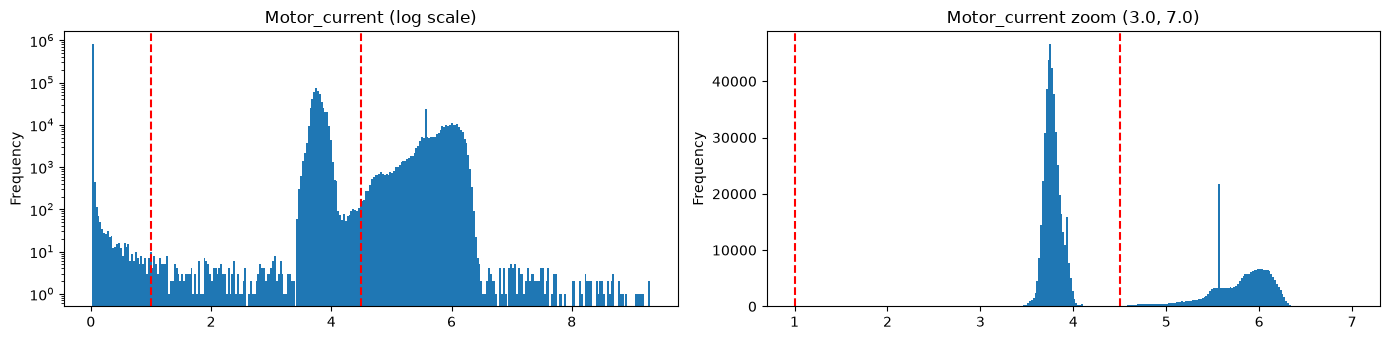

In [47]:
source = result.df[config.state_source_col]
zoom_range = (3.0, 7.0)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
source.plot.hist(bins=300, logy=True, ax=axes[0], title=f"{config.state_source_col} (log scale)")
source[source.between(*zoom_range)].plot.hist(bins=200, ax=axes[1], title=f"{config.state_source_col} zoom {zoom_range}")
for axis in axes:
    for edge in config.state_edges:
        axis.axvline(edge, color="red", linestyle="--")
plt.tight_layout()
plt.show()

In [48]:
display(result.state_summary)

,rows,normal_rows,fault_rows,share_of_normal_pct,share_of_fault_pct
state,,,,,
off,829000,828907,93,55.744,0.310
unloaded,448795,448734,61,30.177,0.204
loaded,239153,209353,29800,14.079,99.486


### Baseline and thresholds per operating state

In [49]:
display(result.baseline_by_state[["state", "n", "median", "Q1", "Q3", "IQR", "MAD_scaled", "p01", "p99"]].round(3))

,state,n,median,Q1,Q3,IQR,MAD_scaled,p01,p99
sensor,,,,,,,,,
TP2,off,828907,-0.012,-0.014,-0.012,0.002,0.003,-0.018,-0.008
TP3,off,828907,8.654,8.356,8.988,0.632,0.466,8.088,9.498
H1,off,828907,8.640,8.344,8.976,0.632,0.466,8.078,9.484
DV_pressure,off,828907,-0.020,-0.022,-0.018,0.004,0.003,-0.026,-0.012
Reservoirs,off,828907,8.654,8.358,8.990,0.632,0.466,8.092,9.498
Oil_temperature,off,828907,59.375,55.900,62.975,7.075,5.189,48.400,68.425
Motor_current,off,828907,0.040,0.040,0.042,0.002,0.004,0.032,0.045
TP2,unloaded,448734,-0.012,-0.014,-0.010,0.004,0.003,-0.026,-0.006
TP3,unloaded,448734,9.646,9.422,9.844,0.422,0.311,8.510,10.174


In [50]:
display(result.thresholds.round(3))

,state,sensor,scale_fallback,iqr_warning_low,iqr_warning_high,mad_warning_low,mad_warning_high,iqr_critical_low,iqr_critical_high,mad_critical_low,mad_critical_high
0,off,TP2,False,-0.017,-0.009,-0.022,-0.002,-0.020,-0.006,-0.030,0.006
1,off,TP3,False,7.408,9.936,7.025,10.283,6.460,10.884,5.861,11.447
2,off,H1,False,7.396,9.924,7.011,10.269,6.448,10.872,5.847,11.433
3,off,DV_pressure,False,-0.028,-0.012,-0.030,-0.010,-0.034,-0.006,-0.038,-0.002
4,off,Reservoirs,False,7.410,9.938,7.025,10.283,6.462,10.886,5.861,11.447
5,off,Oil_temperature,False,45.287,73.588,41.213,77.537,34.675,84.200,28.240,90.510
6,off,Motor_current,False,0.036,0.046,0.027,0.053,0.033,0.050,0.018,0.062
7,unloaded,TP2,False,-0.020,-0.004,-0.022,-0.002,-0.026,0.002,-0.030,0.006
8,unloaded,TP3,False,8.789,10.477,8.556,10.736,8.156,11.110,7.778,11.514
9,unloaded,H1,False,8.777,10.465,8.542,10.722,8.144,11.098,7.764,11.500


### Outlier rates per state
`normal_out_pct` is the false-alarm rate, `fault_out_pct` is the detection rate on labelled failures.

In [51]:
display(result.outliers_pivot)

fault_out_pct                           \
method                             iqr              mad           
level                         critical warning critical warning   
state    sensor                                                   
loaded   DV_pressure             94.66   94.66    94.66   94.66   
         H1                       0.01    1.20     0.01    1.20   
         Motor_current            0.00    0.03     0.00    0.04   
         Oil_temperature          0.00    1.85     0.00    0.00   
         Reservoirs               0.17    1.13     0.08    0.29   
         TP2                      0.06    3.13     0.00    0.16   
         TP3                      0.17    1.13     0.08    0.29   
off      DV_pressure              0.00    2.15     0.00    1.08   
         H1                       1.08    1.08     1.08    1.08   
         Motor_current            1.08    1.08     0.00    1.08   
         Oil_temperature          0.00    1.08     0.00    1.08   
         Reservoirs               0.00    1.08     0.00    1.08   
         TP2                      2.15  100.00     1.08    1.08   
         TP3                      0.00    1.08     0.00    1.08   
unloaded DV_pressure              4.92  100.00     1.64   57.38   
         H1                       0.00    3.28     0.00    0.00   
         Motor_current            0.00    8.20     0.00    0.00   
         Oil_temperature          0.00   14.75     0.00    1.64   
         Reservoirs               0.00    3.28     0.00    0.00   
         TP2                      0.00   19.67     0.00   14.75   
         TP3                      0.00    3.28     0.00    0.00   

                         normal_out_pct                           
method                              iqr              mad          
level                          critical warning critical warning  
state    sensor                                                   
loaded   DV_pressure              19.85   20.03    19.78   19.94  
         H1                        1.32    6.71     2.18    9.88  
         Motor_current             0.03    2.61     0.03    2.65  
         Oil_temperature           0.12    0.84     0.01    0.41  
         Reservoirs                0.84    1.41     0.47    1.20  
         TP2                       3.01    6.52     1.73    4.42  
         TP3                       0.84    1.41     0.46    1.20  
off      DV_pressure               0.00    2.28     0.00    0.16  
         H1                        0.24    0.25     0.24    0.24  
         Motor_current             1.31    7.89     0.09    0.37  
         Oil_temperature           0.00    0.30     0.00    0.05  
         Reservoirs                0.09    0.16     0.05    0.13  
         TP2                       0.36    5.04     0.01    0.02  
         TP3                       0.09    0.16     0.05    0.13  
unloaded DV_pressure               0.70    3.73     0.66    0.93  
         H1                        0.22    2.59     0.16    1.20  
         Motor_current             0.27    1.61     0.22    0.52  
         Oil_temperature           0.29    4.66     0.05    1.70  
         Reservoirs                0.18    2.57     0.01    1.21  
         TP2                       1.14    6.93     0.65    4.56  
         TP3                       0.17    2.55     0.01    1.18

### Labels versus official failure windows
Every row inside a window must be labelled `1`, and no `1` may fall outside the windows.

In [52]:
display(result.failure_check)
print(f"Anomaly labels outside all windows: {result.anomalies_outside_windows}")

,window_start,window_end,rows,labelled_anomaly,unlabelled,status
0,2020-04-18 00:00,2020-04-18 23:59,8657,8657,0,OK
1,2020-05-29 23:30,2020-05-30 06:00,2360,2360,0,OK
2,2020-06-05 10:00,2020-06-07 14:30,17315,17315,0,OK
3,2020-07-15 14:30,2020-07-15 19:00,1622,1622,0,OK


Anomaly labels outside all windows: 0


### Saved files

In [53]:
display(list_output_files(config))

,file,size_kb,path
0,baseline_integrity_summary.json,1.0,C:\Users\compu import\Downloads\outputs\metric...
1,baseline_quality_report.csv,1.1,C:\Users\compu import\Downloads\outputs\metric...
2,healthy_selection_summary.csv,0.2,C:\Users\compu import\Downloads\outputs\metric...
3,official_failure_check.csv,0.3,C:\Users\compu import\Downloads\outputs\metric...
4,outlier_summary_by_state.csv,5.1,C:\Users\compu import\Downloads\outputs\metric...
5,sensor_baseline.csv,2.6,C:\Users\compu import\Downloads\outputs\metric...
6,sensor_baseline_by_state.csv,4.7,C:\Users\compu import\Downloads\outputs\metric...
7,sensor_baseline_by_state_healthy.csv,4.7,C:\Users\compu import\Downloads\outputs\metric...
8,sensor_baseline_healthy.csv,2.6,C:\Users\compu import\Downloads\outputs\metric...
9,sensor_thresholds_by_state.csv,3.6,C:\Users\compu import\Downloads\outputs\metric...


## 12. Using the outputs downstream
```python
thresholds = pd.read_csv("outputs/metrics/sensor_thresholds_by_state.csv")
df["state"] = assign_states(df, config)

limits = thresholds.set_index(["state", "sensor"])
keys = list(zip(df["state"], ["TP3"] * len(df)))
low = limits.loc[keys, "mad_critical_low"].to_numpy()
high = limits.loc[keys, "mad_critical_high"].to_numpy()
is_outlier = (df["TP3"].to_numpy() < low) | (df["TP3"].to_numpy() > high)
```
Digital sensors are excluded from z-scoring and thresholds; use `on_fraction` or state-change rules for them.

## 13. Baseline from the healthy period only
Recomputes the baseline, the per-state baseline and the thresholds from the **healthy period** only.
The existing results above are left unchanged; the new files carry the suffix `_healthy`.

A row is used only when **all** of these hold:
1. its timestamp is inside `[HEALTHY_START, HEALTHY_END]`,
2. `ground_truth == 0`,
3. it is not inside a documented leak-like episode (`HEALTHY_EXCLUDED_EPISODES`),
4. it is not in a **frozen-logger minute**: at least 3 readings in the minute and every analogue signal constant.

The window ends 8 days before the first official failure (18 Apr 2020).
The two excluded episodes (12 Mar and 28-29 Mar 2020) are continuous full-load runs with collapsing reservoir pressure
that are not in the failure report; they come from the audit of the public MetroPT-3 data and should be confirmed on your data.
Set `HEALTHY_EXCLUDED_EPISODES = ()` to keep them.

In [54]:
HEALTHY_START = pd.Timestamp("2020-02-01 00:00:00")
HEALTHY_END = pd.Timestamp("2020-04-10 23:59:59")
HEALTHY_EXCLUDED_EPISODES = (
    ("2020-03-12 00:00:00", "2020-03-12 14:00:00"),
    ("2020-03-28 23:00:00", "2020-03-29 21:00:00"),
)
ANALOG_SIGNALS = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
MIN_ROWS_FOR_FROZEN = 3

In [55]:
def flag_frozen_rows(frame: pd.DataFrame, cfg: BaselineConfig) -> pd.Series:
    minute = frame[cfg.timestamp_col].dt.floor("min")
    keys = [frame["segment"], minute] if "segment" in frame.columns else [minute]
    grouped = frame.groupby(keys)
    spread = (
        grouped[ANALOG_SIGNALS].transform("max") - grouped[ANALOG_SIGNALS].transform("min")
    ).max(axis=1)
    rows_in_minute = grouped[cfg.timestamp_col].transform("size")
    return (rows_in_minute >= MIN_ROWS_FOR_FROZEN) & (spread == 0)


def select_healthy_rows(frame: pd.DataFrame, cfg: BaselineConfig) -> tuple[pd.Series, pd.DataFrame]:
    timestamps = frame[cfg.timestamp_col]
    in_window = timestamps.between(HEALTHY_START, HEALTHY_END)
    is_normal = frame[cfg.label_col].eq(0)
    in_episode = pd.Series(False, index=frame.index)
    for start, end in HEALTHY_EXCLUDED_EPISODES:
        in_episode |= timestamps.between(pd.Timestamp(start), pd.Timestamp(end))
    is_frozen = flag_frozen_rows(frame, cfg)

    mask = in_window & is_normal & ~in_episode & ~is_frozen
    counts = {
        "all rows": len(frame),
        "inside healthy window": int(in_window.sum()),
        "... and ground_truth == 0": int((in_window & is_normal).sum()),
        "... and not in excluded episodes": int((in_window & is_normal & ~in_episode).sum()),
        "... and not frozen (final)": int(mask.sum()),
    }
    steps = pd.DataFrame({"rows": counts})
    steps["removed_by_step"] = (-steps["rows"].diff()).astype("Int64")
    return mask, steps

In [56]:
healthy_mask, healthy_selection = select_healthy_rows(result.df, config)
healthy_df = result.df.loc[healthy_mask]
display(healthy_selection)

,rows,removed_by_step
all rows,1516948,<NA>
inside healthy window,515619,1001329
... and ground_truth == 0,515619,0
... and not in excluded episodes,503006,12613
... and not frozen (final),502862,144


In [57]:
sensor_types = dict(zip(result.quality["sensor"], result.quality["sensor_type"]))

healthy_baseline = compute_baseline(healthy_df, result.sensors, config, sensor_types)
healthy_baseline_by_state = compute_baseline_by_state(healthy_df, result.analogue_sensors, config, sensor_types)
healthy_thresholds = build_thresholds(healthy_baseline_by_state, config)

display(healthy_baseline.round(4))

15:40:58 | INFO     | Using 502862 / 502862 rows (100.0%) as normal baseline data.
15:41:00 | INFO     | Using 323733 / 323733 rows (100.0%) as normal baseline data.
15:41:01 | INFO     | Using 131150 / 131150 rows (100.0%) as normal baseline data.
15:41:02 | INFO     | Using 47979 / 47979 rows (100.0%) as normal baseline data.


,n,mean,std,median,Q1,Q3,IQR,MAD,MAD_scaled,min,max,p01,p99,n_unique,sensor_type,on_fraction,zscore_usable
sensor,,,,,,,,,,,,,,,,,
TP2,502862,0.8384,2.6786,-0.0120,-0.0140,-0.010,0.0040,0.002,0.0030,-0.032,10.652,-0.0240,10.286,4446,analogue,NaN,True
TP3,502862,9.0082,0.5934,8.9920,8.5160,9.486,0.9700,0.484,0.7176,0.886,10.266,8.0700,10.110,1821,analogue,NaN,True
H1,502862,8.1276,2.6938,8.8600,8.3620,9.394,1.0320,0.514,0.7621,-0.034,10.266,-0.0240,10.086,1821,analogue,NaN,True
DV_pressure,502862,-0.0101,0.1371,-0.0220,-0.0240,-0.018,0.0060,0.002,0.0030,-0.032,9.844,-0.0280,0.414,1176,analogue,NaN,True
Reservoirs,502862,9.0088,0.5926,8.9920,8.5180,9.488,0.9700,0.484,0.7176,0.866,10.266,8.0740,10.108,1811,analogue,NaN,True
Oil_temperature,502862,59.0587,5.7135,58.0750,55.4250,62.175,6.7500,3.150,4.6702,15.400,77.825,47.2500,73.350,1797,analogue,NaN,True
Motor_current,502862,1.5766,2.1412,0.0425,0.0375,3.770,3.7325,0.005,0.0074,0.020,9.295,0.0325,6.185,1393,analogue,NaN,True
COMP,502862,0.9046,0.2937,1.0000,1.0000,1.000,0.0000,0.000,0.0000,0.000,1.000,0.0000,1.000,2,digital,0.9046,False
DV_eletric,502862,0.0954,0.2938,0.0000,0.0000,0.000,0.0000,0.000,0.0000,0.000,1.000,0.0000,1.000,2,digital,0.0954,False


In [58]:
display(
    healthy_baseline_by_state[["state", "n", "median", "Q1", "Q3", "IQR", "MAD_scaled", "p01", "p99"]].round(3)
)
display(healthy_thresholds.round(3))

,state,n,median,Q1,Q3,IQR,MAD_scaled,p01,p99
sensor,,,,,,,,,
TP2,off,323733,-0.014,-0.014,-0.012,0.002,0.003,-0.018,-0.008
TP3,off,323733,8.714,8.390,9.064,0.674,0.498,8.080,9.522
H1,off,323733,8.702,8.378,9.050,0.672,0.498,8.068,9.508
DV_pressure,off,323733,-0.022,-0.024,-0.018,0.006,0.003,-0.028,-0.012
Reservoirs,off,323733,8.716,8.390,9.064,0.674,0.498,8.082,9.524
Oil_temperature,off,323733,57.000,54.700,59.175,4.475,3.262,46.975,66.475
Motor_current,off,323733,0.040,0.038,0.042,0.005,0.004,0.032,0.045
TP2,unloaded,131150,-0.012,-0.014,-0.010,0.004,0.003,-0.026,-0.006
TP3,unloaded,131150,9.682,9.514,9.856,0.342,0.252,8.496,10.156


,state,sensor,scale_fallback,iqr_warning_low,iqr_warning_high,mad_warning_low,mad_warning_high,iqr_critical_low,iqr_critical_high,mad_critical_low,mad_critical_high
0,off,TP2,False,-0.017,-0.009,-0.024,-0.004,-0.020,-0.006,-0.032,0.004
1,off,TP3,False,7.379,10.075,6.970,10.458,6.368,11.086,5.725,11.703
2,off,H1,False,7.370,10.058,6.958,10.446,6.362,11.066,5.713,11.691
3,off,DV_pressure,False,-0.033,-0.009,-0.032,-0.012,-0.042,0.000,-0.040,-0.004
4,off,Reservoirs,False,7.379,10.075,6.972,10.460,6.368,11.086,5.727,11.705
5,off,Oil_temperature,False,47.987,65.888,45.584,68.416,41.275,72.600,37.430,76.570
6,off,Motor_current,False,0.030,0.050,0.027,0.053,0.023,0.057,0.018,0.062
7,unloaded,TP2,False,-0.020,-0.004,-0.022,-0.002,-0.026,0.002,-0.030,0.006
8,unloaded,TP3,False,9.001,10.369,8.800,10.564,8.488,10.882,8.170,11.194
9,unloaded,H1,False,8.984,10.360,8.775,10.561,8.468,10.876,8.138,11.198


### Healthy-period baseline versus the baseline above
Relative change of `std` and `IQR` for the analogue sensors (negative = narrower than the earlier baseline).

In [59]:
analogue = result.analogue_sensors
comparison = pd.DataFrame({
    "n_before": result.baseline.loc[analogue, "n"],
    "n_healthy": healthy_baseline.loc[analogue, "n"],
    "std_before": result.baseline.loc[analogue, "std"],
    "std_healthy": healthy_baseline.loc[analogue, "std"],
    "IQR_before": result.baseline.loc[analogue, "IQR"],
    "IQR_healthy": healthy_baseline.loc[analogue, "IQR"],
})
comparison["std_change_pct"] = 100 * (comparison["std_healthy"] / comparison["std_before"] - 1)
comparison["IQR_change_pct"] = 100 * (comparison["IQR_healthy"] / comparison["IQR_before"] - 1)
display(comparison.round(4))

,n_before,n_healthy,std_before,std_healthy,IQR_before,IQR_healthy,std_change_pct,IQR_change_pct
sensor,,,,,,,,
TP2,1486994,502862,3.1347,2.6786,0.004,0.0040,-14.5516,0.0000
TP3,1486994,502862,0.6338,0.5934,0.996,0.9700,-6.3850,-2.6104
H1,1486994,502862,3.1876,2.6938,1.108,1.0320,-15.4913,-6.8592
DV_pressure,1486994,502862,0.2773,0.1371,0.004,0.0060,-50.5543,50.0000
Reservoirs,1486994,502862,0.6331,0.5926,0.996,0.9700,-6.3906,-2.6104
Oil_temperature,1486994,502862,6.3004,5.7135,9.300,6.7500,-9.3148,-27.4194
Motor_current,1486994,502862,2.2703,2.1412,3.755,3.7325,-5.6860,-0.5992


In [60]:
config.output_dir.mkdir(parents=True, exist_ok=True)
healthy_baseline.to_csv(config.output_dir / "sensor_baseline_healthy.csv")
healthy_baseline_by_state.to_csv(config.output_dir / "sensor_baseline_by_state_healthy.csv")
healthy_thresholds.to_csv(config.output_dir / "sensor_thresholds_by_state_healthy.csv", index=False)
healthy_selection.to_csv(config.output_dir / "healthy_selection_summary.csv")
display(list_output_files(config))

,file,size_kb,path
0,baseline_integrity_summary.json,1.0,C:\Users\compu import\Downloads\outputs\metric...
1,baseline_quality_report.csv,1.1,C:\Users\compu import\Downloads\outputs\metric...
2,healthy_selection_summary.csv,0.2,C:\Users\compu import\Downloads\outputs\metric...
3,official_failure_check.csv,0.3,C:\Users\compu import\Downloads\outputs\metric...
4,outlier_summary_by_state.csv,5.1,C:\Users\compu import\Downloads\outputs\metric...
5,sensor_baseline.csv,2.6,C:\Users\compu import\Downloads\outputs\metric...
6,sensor_baseline_by_state.csv,4.7,C:\Users\compu import\Downloads\outputs\metric...
7,sensor_baseline_by_state_healthy.csv,4.7,C:\Users\compu import\Downloads\outputs\metric...
8,sensor_baseline_healthy.csv,2.6,C:\Users\compu import\Downloads\outputs\metric...
9,sensor_thresholds_by_state.csv,3.6,C:\Users\compu import\Downloads\outputs\metric...
